## 1. Verify the dataset and the provided split

We use train.xlsx and test.xlsx without changing the train/test split.
Each ultrasound image is paired with a mask with the same filename in
the labels folder. We check for duplicate entries, overlap between the
two splits, and missing files.

In [1]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path(
    "/mnt/cv_data/users/seven/datasets/Dataset_BUSI_with_GT_Clean"
)

train_df = pd.read_excel(DATA_ROOT / "train.xlsx")
test_df = pd.read_excel(DATA_ROOT / "test.xlsx")

# Check that image names are present and unique within each split.
for split_name, df in [("Train", train_df), ("Test", test_df)]:
    assert df["Image"].notna().all(), f"{split_name}: missing image names"
    assert df["Image"].is_unique, f"{split_name}: duplicate image names"

# The test images must not appear in the training set.
overlap = set(train_df["Image"]) & set(test_df["Image"])
assert not overlap, f"Train/test overlap: {overlap}"

# Every listed image must have a corresponding mask.
missing = []

for name in pd.concat([train_df["Image"], test_df["Image"]]):
    for folder in ["images", "labels"]:
        path = DATA_ROOT / folder / name
        if not path.is_file():
            missing.append(str(path))

assert not missing, f"Missing files: {missing[:10]}"

print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("Train/test filename overlap:", len(overlap))
print("All listed images and masks exist.")

Training images: 517
Testing images: 130
Train/test filename overlap: 0
All listed images and masks exist.


## 2. Visualize a training image and its segmentation mask

We display an original image, its mask, and an overlay to check spatial
alignment. The mask is read directly to preserve its palette indices
(0 and 1). The highlighted region in the overlay represents label 1.

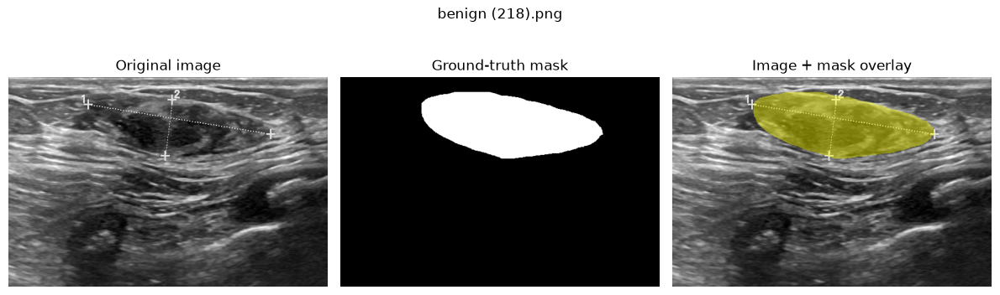

Image shape: (396, 602)
Mask values: [0 1]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Use a training example for the initial visual inspection.
name = train_df.iloc[0]["Image"]

with Image.open(DATA_ROOT / "images" / name) as img:
    image = np.array(img.convert("L"))

# Preserve the mask's original label values.
with Image.open(DATA_ROOT / "labels" / name) as img:
    mask = np.array(img)

assert mask.ndim == 2, f"Unexpected mask shape: {mask.shape}"
assert image.shape == mask.shape, "Image and mask sizes do not match."
assert set(np.unique(mask)).issubset({0, 1}), "Unexpected mask values."

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image, cmap="gray")
axes[2].imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="autumn",
    alpha=0.45,
    vmin=0,
    vmax=1,
)
axes[2].set_title("Image + mask overlay")

for ax in axes:
    ax.axis("off")

fig.suptitle(name)
plt.tight_layout()
plt.show()

print("Image shape:", image.shape)
print("Mask values:", np.unique(mask))

## 3. Preprocessing and data loading

We retain the training and testing splits provided in the Excel files.
Images are converted to grayscale, resized to 256 × 256, and normalized
to [0, 1]. Masks are resized using nearest-neighbor interpolation to
preserve binary labels.

We use a random seed of 42 and a batch size of 8. No data augmentation
is applied in this initial setup. The training loader shuffles images;
the test loader preserves their order. Test data is not used to select
hyperparameters or training checkpoints.

In [3]:
import random
import torch
from torch.utils.data import Dataset, DataLoader

SEED = 42
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


class BUSISegmentationDataset(Dataset):
    def __init__(self, dataframe, root):
        self.names = dataframe["Image"].tolist()
        self.root = Path(root)

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        name = self.names[index]

        with Image.open(self.root / "images" / name) as img:
            original_size = img.size
            img = img.convert("L")
            img = img.resize(
                IMAGE_SIZE,
                resample=Image.Resampling.BILINEAR,
            )
            image = np.array(img, dtype=np.float32) / 255.0

        with Image.open(self.root / "labels" / name) as label:
            # Validate the original mask before resizing.
            assert label.size == original_size, f"Size mismatch: {name}"
            raw_mask = np.array(label)
            assert raw_mask.ndim == 2, f"Unexpected mask shape: {name}"
            assert set(np.unique(raw_mask)).issubset({0, 1}), (
                f"Unexpected mask values: {name}"
            )

            label = label.resize(
                IMAGE_SIZE,
                resample=Image.Resampling.NEAREST,
            )
            mask = np.array(label, dtype=np.float32)

        # Add the channel dimension: [height, width] -> [1, height, width].
        image = torch.from_numpy(image).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask, name


train_dataset = BUSISegmentationDataset(train_df, DATA_ROOT)
test_dataset = BUSISegmentationDataset(test_df, DATA_ROOT)

# A dedicated generator makes the training shuffle reproducible.
generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# Inspect one batch without performing any training.
images, masks, names = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image range:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks).tolist())
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Image batch shape: torch.Size([8, 1, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image range: 0.0 1.0
Mask values: [0.0, 1.0]
Training batches: 65
Testing batches: 17


## 4. Define the DeepLabV3+ model

DeepLabV3+ has three parts:

1. **Encoder (backbone).** A ResNet-50 extracts features. In its last
   stage, strides are replaced by dilated (atrous) convolutions, so the
   final feature map has 1/16 of the input resolution instead of 1/32.
   This keeps more spatial detail.
2. **ASPP (Atrous Spatial Pyramid Pooling).** Five parallel branches look
   at the encoder output with different receptive fields: a 1 × 1
   convolution, three 3 × 3 convolutions with dilation rates 6, 12 and
   18, and a global average pooling branch. Their outputs are
   concatenated and fused by a 1 × 1 convolution.
3. **Decoder.** The ASPP output is upsampled by 4 and concatenated with
   low-level features from the first ResNet stage (1/4 resolution),
   which carry fine boundary information. Two 3 × 3 convolutions refine
   the result, and a 1 × 1 convolution produces one logit per pixel. The
   logits are upsampled to the input size.

For a fair comparison with U-Net, the network is trained from scratch
(no ImageNet weights), takes the same single-channel image in [0, 1], and
outputs raw logits. No sigmoid is applied inside the model because the
training loss uses BCEWithLogitsLoss. Note that this model has far more
parameters than our U-Net, which should be kept in mind when comparing
the results.

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet50


def conv_bn_relu(in_ch, out_ch, kernel_size=3, dilation=1):
    """Convolution + BatchNorm + ReLU; padding keeps height and width unchanged."""
    padding = 0 if kernel_size == 1 else dilation * (kernel_size - 1) // 2
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size,
                  padding=padding, dilation=dilation, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class ASPP(nn.Module):
    """Atrous Spatial Pyramid Pooling: parallel branches with different dilation rates."""

    def __init__(self, in_ch, out_ch=256, rates=(6, 12, 18)):
        super().__init__()

        # One 1x1 branch plus one dilated 3x3 branch for every rate.
        self.branches = nn.ModuleList(
            [conv_bn_relu(in_ch, out_ch, kernel_size=1)]
            + [conv_bn_relu(in_ch, out_ch, kernel_size=3, dilation=r) for r in rates]
        )

        # Global context branch. It has no BatchNorm because its feature map is
        # 1 x 1, and BatchNorm fails if the last batch contains a single image.
        self.image_pool = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
        )

        # Fuse the concatenated branches (len(rates) + 2 branches in total).
        self.project = nn.Sequential(
            conv_bn_relu(out_ch * (len(rates) + 2), out_ch, kernel_size=1),
            nn.Dropout(0.5),
        )

    def forward(self, x):
        features = [branch(x) for branch in self.branches]

        pooled = self.image_pool(x)                     # [B, out_ch, 1, 1]
        pooled = F.interpolate(                         # back to the feature-map size
            pooled, size=x.shape[-2:], mode="bilinear", align_corners=False
        )
        features.append(pooled)

        return self.project(torch.cat(features, dim=1))


class DeepLabV3Plus(nn.Module):
    """DeepLabV3+ with a ResNet-50 encoder for single-channel binary segmentation."""

    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()

        # ResNet-50 without pretrained weights. Dilation in the last stage gives
        # output stride 16 (feature map = 1/16 of the input size).
        backbone = resnet50(
            weights=None, replace_stride_with_dilation=[False, False, True]
        )
        # The first convolution is replaced to accept grayscale input.
        backbone.conv1 = nn.Conv2d(
            in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False
        )

        self.stem = nn.Sequential(
            backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool
        )
        self.layer1 = backbone.layer1   # 256 channels, 1/4 resolution (low-level features)
        self.layer2 = backbone.layer2   # 512 channels, 1/8
        self.layer3 = backbone.layer3   # 1024 channels, 1/16
        self.layer4 = backbone.layer4   # 2048 channels, 1/16 (dilated)

        self.aspp = ASPP(in_ch=2048, out_ch=256)

        # Decoder: reduce the low-level features to 48 channels, then fuse.
        self.low_level = conv_bn_relu(256, 48, kernel_size=1)
        self.decoder = nn.Sequential(
            conv_bn_relu(256 + 48, 256, kernel_size=3),
            conv_bn_relu(256, 256, kernel_size=3),
        )

        # One raw prediction score (logit) per pixel.
        self.classifier = nn.Conv2d(256, out_channels, kernel_size=1)

    def forward(self, x):
        input_size = x.shape[-2:]

        # Encoder
        x = self.stem(x)
        low = self.layer1(x)
        x = self.layer4(self.layer3(self.layer2(low)))

        # Multi-scale context
        x = self.aspp(x)

        # Decoder: upsample to 1/4 resolution and fuse with low-level features
        x = F.interpolate(x, size=low.shape[-2:], mode="bilinear", align_corners=False)
        x = self.decoder(torch.cat([x, self.low_level(low)], dim=1))

        # Logits at full input resolution
        x = self.classifier(x)
        return F.interpolate(x, size=input_size, mode="bilinear", align_corners=False)


# Shape check with one batch from the Section 3 loader (no training).
check_model = DeepLabV3Plus(in_channels=1, out_channels=1)
n_params = sum(p.numel() for p in check_model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params / 1e6:.1f} M")

check_model.eval()
with torch.no_grad():
    check_out = check_model(images[:2])
print("Input:", tuple(images[:2].shape), "-> output:", tuple(check_out.shape))
assert check_out.shape == (2, 1, 256, 256), "Output must match the 256 x 256 mask size"
del check_model, check_out

Trainable parameters: 40.3 M
Input: (2, 1, 256, 256) -> output: (2, 1, 256, 256)


## 5. Define the training loss

We combine binary cross-entropy with soft Dice loss, using equal weights.

BCEWithLogitsLoss evaluates pixel-level predictions directly from logits.
Soft Dice loss measures overlap between predicted probabilities and the
ground-truth mask. Smaller loss indicates better agreement.

The Dice loss used for optimization is different from the binary Dice
metric used for final evaluation.a

In [5]:
bce_loss = nn.BCEWithLogitsLoss()


def segmentation_loss(logits, targets):
    # Pixel-level binary cross-entropy.
    bce = bce_loss(logits, targets)

    # Convert raw scores into probabilities.
    probabilities = torch.sigmoid(logits)

    # Calculate soft Dice separately for each image.
    dims = (1, 2, 3)
    intersection = (probabilities * targets).sum(dim=dims)
    total = probabilities.sum(dim=dims) + targets.sum(dim=dims)

    smooth = 1e-6
    soft_dice = (2 * intersection + smooth) / (total + smooth)
    dice_loss = 1 - soft_dice.mean()

    return 0.5 * bce + 0.5 * dice_loss


print("Loss function is ready.")

Loss function is ready.


## 6. Train DeepLabV3+ on the allocated GPU

We train from scratch for 50 epochs using Adam with a learning rate of
0.001, the same loss, batch size, seed, preprocessing and training set
as for U-Net. Only the provided training set is used for optimization,
and no data augmentation is applied.

We reset the random seeds and the training-loader generator before
training. After every epoch, the training loss is appended to a CSV file
and the latest checkpoint is saved. After the last epoch, the final
model weights are saved in a separate `weights/` folder. All outputs of
one run are stored in `outputs/deeplabv3plus/job_<id>/`, where `<id>` is
the Slurm job number.

Training runs on a GPU through Slurm (`TRAIN = True`). To inspect an
existing run without training again, set `TRAIN = False` and enter the
run folder name in `RUN_NAME`. As for U-Net, there is no validation set,
so the weights of the final epoch are used and the test set is never
used to select a checkpoint.

## 7. Locate the trained model and review training history

The model was trained independently through Slurm using
`train_deeplabv3plus.py`. We load the saved training records and locate
the final weights without repeating training.

If multiple completed runs exist, we select the intended run explicitly.
The test set is not used to choose a training run.

Completed DeepLabV3+ runs:
/mnt/cv_data/users/seven/Instruction3/outputs/deeplabv3plus/job_387/weights/deeplabv3plus_final.pth

Selected run: job_387
Weights: /mnt/cv_data/users/seven/Instruction3/outputs/deeplabv3plus/job_387/weights/deeplabv3plus_final.pth
Settings: {'model': 'deeplabv3plus', 'seed': 42, 'image_size': [256, 256], 'batch_size': 8, 'epochs': 50, 'optimizer': 'Adam', 'learning_rate': 0.001, 'loss': '0.5 * BCEWithLogits + 0.5 * soft Dice', 'augmentation': 'none', 'pretrained': False, 'train_images': 517, 'slurm_job_id': '387'}
Completed epochs: 50
Final training loss: 0.0671649107014187
SciPy available: True


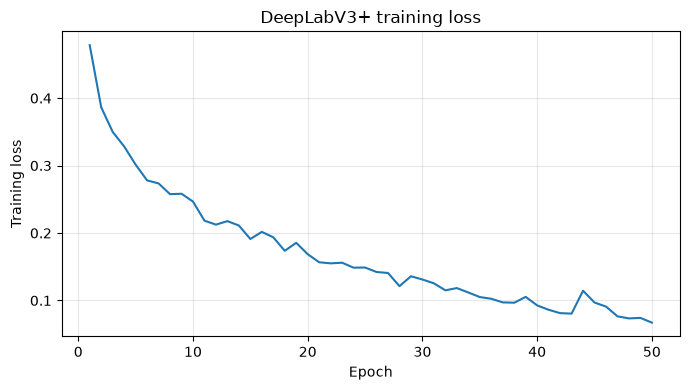

In [6]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import importlib.util

PROJECT_ROOT = Path("/mnt/cv_data/users/seven/Instruction3")
MODEL_NAME = "deeplabv3plus"
WEIGHT_NAME = "deeplabv3plus_final.pth"

# Find completed runs containing final DeepLabV3+ weights.
weight_files = sorted(
    (PROJECT_ROOT / "outputs" / MODEL_NAME).glob(f"job_*/weights/{WEIGHT_NAME}")
)

print("Completed DeepLabV3+ runs:")
for path in weight_files:
    print(path)

if not weight_files:
    raise FileNotFoundError(f"No {WEIGHT_NAME} was found.")

# If multiple runs exist, enter the intended folder name below,
# for example: RUN_NAME = "job_12345"
RUN_NAME = None

if RUN_NAME is not None:
    WEIGHTS_PATH = (
        PROJECT_ROOT / "outputs" / MODEL_NAME
        / RUN_NAME / "weights" / WEIGHT_NAME
    )
    if not WEIGHTS_PATH.is_file():
        raise FileNotFoundError(WEIGHTS_PATH)
elif len(weight_files) == 1:
    WEIGHTS_PATH = weight_files[0]
else:
    raise ValueError(
        "Multiple runs found. Set RUN_NAME to your completed job folder."
    )

RUN_DIR = WEIGHTS_PATH.parent.parent

with open(RUN_DIR / "config.json") as file:
    config = json.load(file)

history = pd.read_csv(RUN_DIR / "training_history.csv")

print("\nSelected run:", RUN_DIR.name)
print("Weights:", WEIGHTS_PATH)
print("Settings:", config)
print("Completed epochs:", history["epoch"].iloc[-1])
print("Final training loss:", history["train_loss"].iloc[-1])
print("SciPy available:", importlib.util.find_spec("scipy") is not None)

plt.figure(figsize=(7, 4))
plt.plot(history["epoch"], history["train_loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("DeepLabV3+ training loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_DIR / "training_curve.png", dpi=120)
plt.show()

## 8. Predict the test set and save the predicted masks

We load the final trained weights into the same DeepLabV3+ architecture
defined in Section 4 (1 input channel, 1 output channel, ResNet-50
encoder trained from scratch) and switch the model to evaluation mode
with `model.eval()`, which fixes the behavior of BatchNorm and Dropout.

The test images come from `test_loader`, which uses exactly the same
preprocessing as training: grayscale, 256 × 256, values in [0, 1]. We
run the model without computing gradients (`torch.no_grad()`) and apply
a sigmoid function to convert logits into tumor probabilities.
Probabilities above 0.5 become 1 (tumor); all other pixels become 0
(background). This gives one binary mask for each test image.

Each prediction is saved as a PNG file with the same filename as its
ground-truth mask, in a separate `pred_masks/` folder (the weights are
in `weights/`). Tumor pixels are saved as 255 so the masks are visible
in an image viewer. The evaluation code treats every non-zero pixel as
tumor, so this does not affect the metrics.

In [7]:
import numpy as np
import torch
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# Rebuild the architecture from Section 4 with the same settings as training.
model = DeepLabV3Plus(in_channels=1, out_channels=1).to(device)

# Load the final weights (strict loading raises an error if shapes differ).
state = torch.load(WEIGHTS_PATH, map_location=device)
if isinstance(state, dict) and "model_state_dict" in state:
    state = state["model_state_dict"]      # in case a full checkpoint was saved
model.load_state_dict(state)
model.eval()                               # fixes the behavior of Dropout/BatchNorm

# Predicted masks are stored separately from the weights.
PRED_DIR = RUN_DIR / "pred_masks"
PRED_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.5
test_names = test_df["Image"].tolist()     # order of test.xlsx
saved_names = []

with torch.no_grad():                      # inference only, no gradients
    for images, masks, names in test_loader:
        images = images.to(device)

        logits = model(images)                         # [B, 1, 256, 256]
        probabilities = torch.sigmoid(logits)          # logits -> probabilities
        predictions = (probabilities > THRESHOLD).cpu().numpy()[:, 0]  # [B, 256, 256]

        for pred, name in zip(predictions, names):
            assert pred.shape == IMAGE_SIZE, f"Unexpected shape for {name}"
            # Save as PNG with the same filename as the ground-truth mask.
            Image.fromarray(pred.astype(np.uint8) * 255).save(
                PRED_DIR / name, format="PNG"
            )
            saved_names.append(name)

# Sanity checks: every test image has a prediction, in the expected order.
assert saved_names == test_names, "Saved predictions do not match test.xlsx"
print(f"Saved {len(saved_names)} predicted masks to {PRED_DIR}")

# Quick check that the model is not predicting all-empty masks.
empty = sum(
    not np.array(Image.open(PRED_DIR / n)).any() for n in test_names
)
print(f"Images with an empty predicted mask: {empty} / {len(test_names)}")

Device: cpu
Saved 130 predicted masks to /mnt/cv_data/users/seven/Instruction3/outputs/deeplabv3plus/job_387/pred_masks
Images with an empty predicted mask: 1 / 130


## 9. Evaluate with Dice, IoU and HD95

We compare each predicted mask with its ground-truth mask using three
standard segmentation metrics. Let P be the predicted tumor region and
G the ground-truth tumor region.

- **Dice coefficient** = 2|P ∩ G| / (|P| + |G|). It measures the overlap
  between prediction and ground truth, from 0 (no overlap) to 1
  (perfect). Higher is better.
- **Intersection over Union (IoU)** = |P ∩ G| / |P ∪ G|. It is also an
  overlap measure, but stricter than Dice because the denominator is the
  union. Higher is better.
- **HD95 (95th-percentile Hausdorff distance)** is the 95th percentile of
  the distances (in pixels) between the boundary of P and the boundary
  of G, taken in both directions. It measures boundary error: a small
  value means the predicted outline is close to the true outline. Using
  the 95th percentile instead of the maximum makes it robust to a few
  outlier pixels. Lower is better.

Dice and IoU focus on region overlap, while HD95 focuses on boundary
accuracy, so together they give a more complete picture.

All three models use the same `evaluate.py` and the same conventions,
computed on the 256 × 256 masks. If both masks are empty, Dice = IoU = 1
and HD95 = 0. If only one of them is empty, Dice and IoU are 0 and HD95
is undefined; those images are excluded from the HD95 average and their
number is reported. The per-image results are saved to `metrics.csv`.

In [8]:
import sys

# Make sure the shared evaluation module in the project folder can be imported.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import evaluate

IMG_DIR = DATA_ROOT / "images"
GT_DIR = DATA_ROOT / "labels"

# Per-image Dice, IoU and HD95, with mean ± std printed over the test set.
metrics_df = evaluate.evaluate_folder(
    pred_dir=PRED_DIR,
    gt_dir=GT_DIR,
    names=test_names,
    save_csv=RUN_DIR / "metrics.csv",
)

# Test-set averages (these are the numbers for the comparison table).
summary = metrics_df[["dice", "iou", "hd95"]].agg(["mean", "std"]).round(4)
display(summary)

# Inspect images where the model predicted no tumor at all.
for name in test_names:
    pred_area = int(evaluate.load_mask(PRED_DIR / name).sum())
    gt_area = int(evaluate.load_mask(GT_DIR / name).sum())
    if pred_area == 0:
        print(f"Empty prediction: {name} | ground-truth tumor pixels: {gt_area}")

# Show the 5 test images with the lowest Dice for a first look at failures.
display(metrics_df.sort_values("dice").head(5).round(4))

Dice : 0.7901 ± 0.2399
IoU  : 0.7019 ± 0.2527
HD95 : 24.25 ± 30.97 px (1 images with undefined HD95 skipped)


,dice,iou,hd95
mean,0.7901,0.7019,24.2510
std,0.2399,0.2527,30.9692


Empty prediction: benign (294).png | ground-truth tumor pixels: 4950


,name,dice,iou,hd95
39,benign (294).png,0.0000,0.0000,NaN
104,benign (402).png,0.0000,0.0000,96.6900
108,malignant (157).png,0.0000,0.0000,145.0670
42,malignant (181).png,0.0095,0.0048,164.1859
96,malignant (45).png,0.0681,0.0353,94.8448


## 10. Visualize the test results

Numbers alone do not show where a model fails, so we display every test
image in pages of eight. Each row contains four panels:

1. the original ultrasound image;
2. the ground-truth mask;
3. the predicted mask (the per-image Dice score is in the title);
4. an overlay on the original image with color-coded errors:
   - **yellow**: correctly predicted tumor (true positive),
   - **red**: predicted tumor that is not in the ground truth (false
     positive, i.e. over-segmentation),
   - **green**: tumor in the ground truth that the model missed (false
     negative, i.e. under-segmentation).

When reviewing the images, look for missed tumors, over- or
under-segmented regions, and inaccurate boundaries. The figures are also
saved as PNG files so they can be reused in `segmentation_comparison.md`.

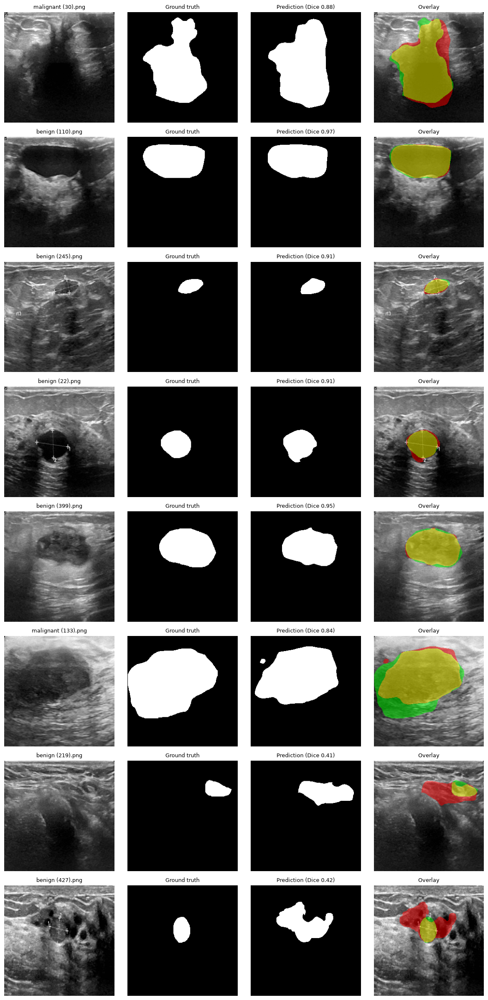

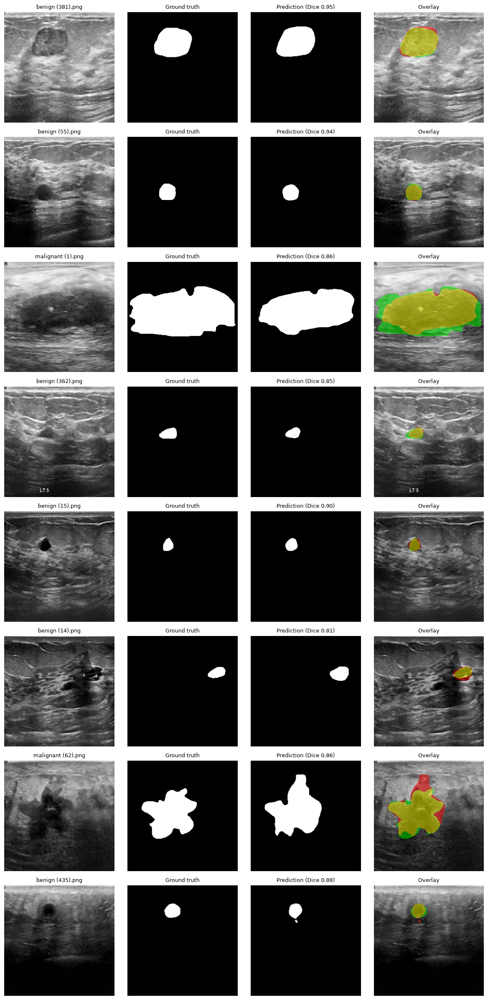

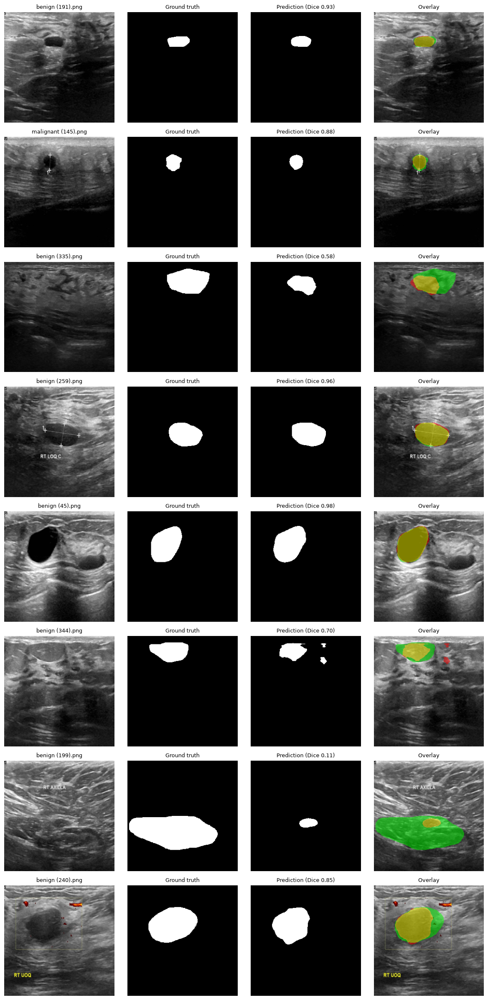

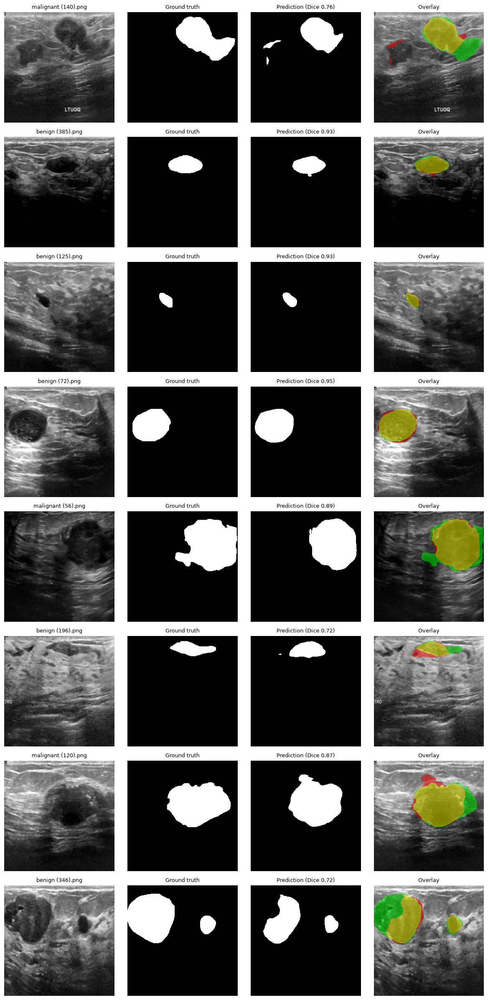

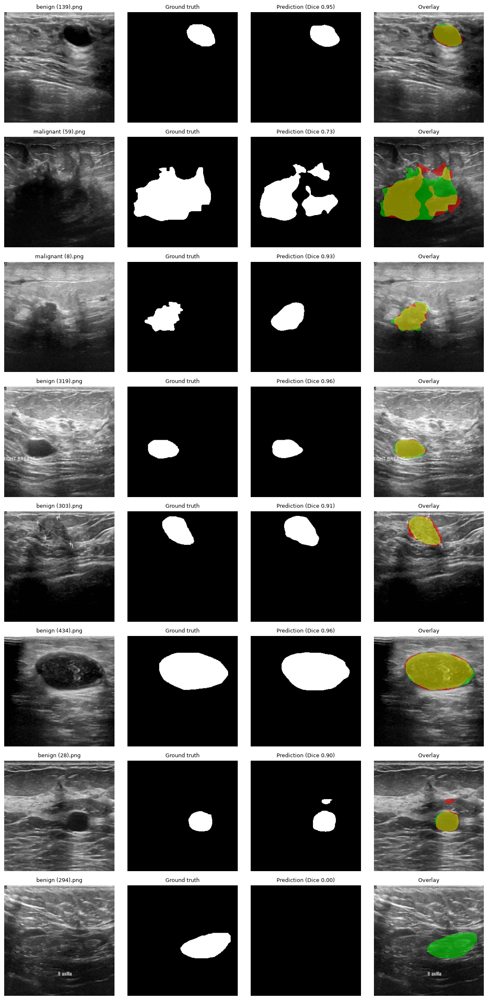

...

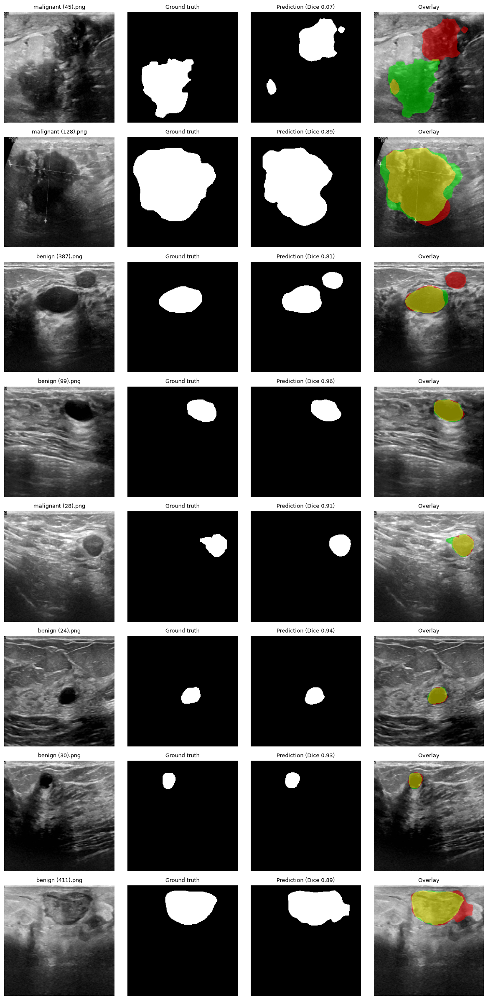

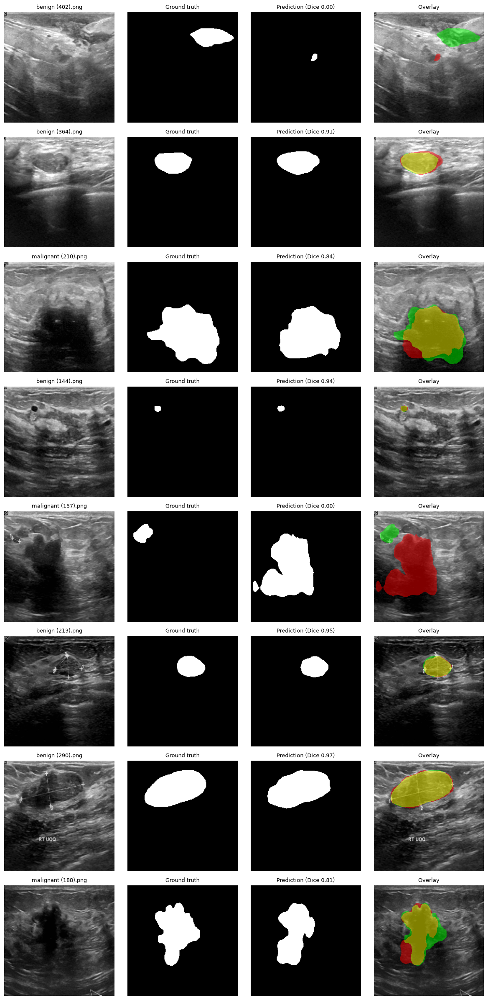

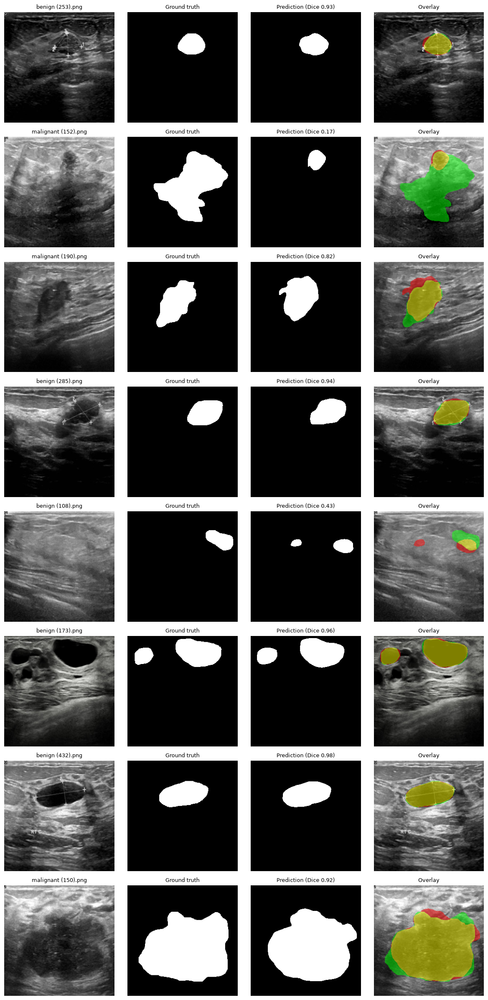

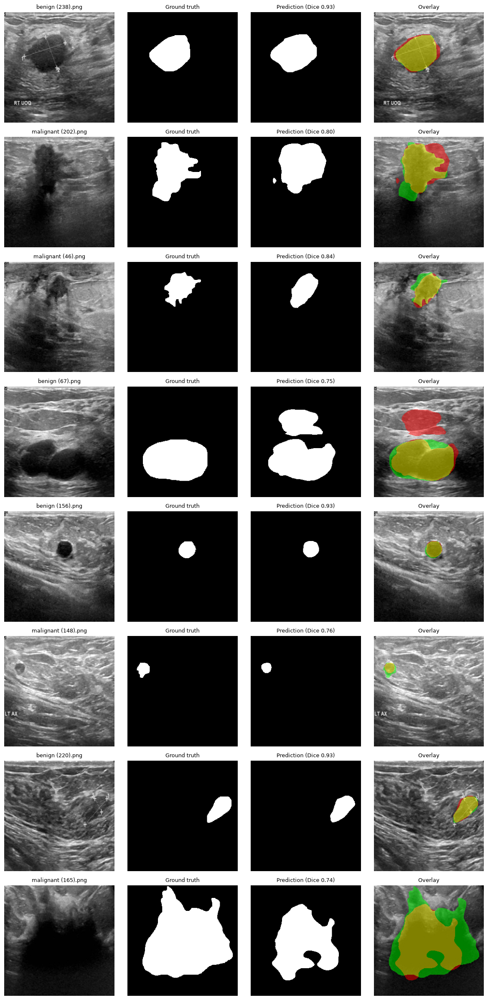

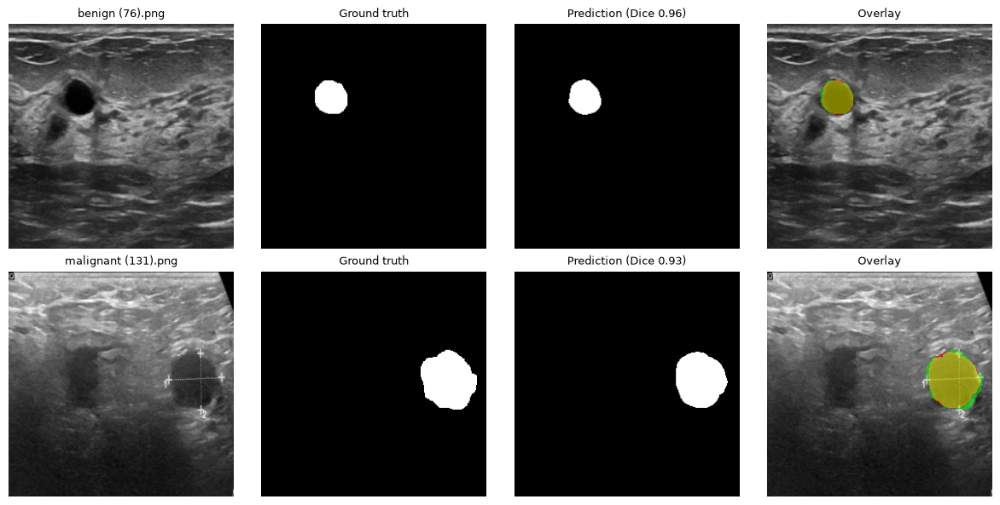

In [9]:
VIS_DIR = RUN_DIR / "visualizations"
VIS_DIR.mkdir(exist_ok=True)

PER_PAGE = 8   # images per figure, keeps every panel readable

# Display all test images: image | ground truth | prediction | error overlay.
for start in range(0, len(test_names), PER_PAGE):
    evaluate.show_results(
        img_dir=IMG_DIR,
        gt_dir=GT_DIR,
        pred_dir=PRED_DIR,
        names=test_names,
        start=start,
        count=PER_PAGE,
        save_path=VIS_DIR / f"vis_{start:03d}.png",
    )

## 11. Supplementary statistics

The mean Dice hides the difference between good and failed cases, and
the HD95 mean above excludes images where HD95 is undefined (the
prediction is empty). To make the comparison between models fair, we
also report the median, the number of failed cases, and an HD95 variant
in which undefined values are replaced by the image diagonal
(256 × √2 ≈ 362 px), the largest possible distance. This variant
penalizes missed tumors instead of ignoring them.

In [10]:
import numpy as np

DIAGONAL = 256 * np.sqrt(2)   # largest possible distance in a 256 x 256 image

n = len(metrics_df)
hd95_penalized = metrics_df["hd95"].fillna(DIAGONAL)

print(f"Median Dice: {metrics_df['dice'].median():.4f}")
print(f"Median IoU : {metrics_df['iou'].median():.4f}")
print(f"Images with Dice = 0   : {(metrics_df['dice'] == 0).sum()} / {n}")
print(f"Images with Dice < 0.5 : {(metrics_df['dice'] < 0.5).sum()} / {n}")
print(f"Images with Dice >= 0.8: {(metrics_df['dice'] >= 0.8).sum()} / {n}")
print(f"HD95 (excluding undefined): {metrics_df['hd95'].mean():.2f} px "
      f"({metrics_df['hd95'].isna().sum()} excluded)")
print(f"HD95 (undefined set to {DIAGONAL:.0f} px): {hd95_penalized.mean():.2f} px")

Median Dice: 0.8869
Median IoU : 0.7968
Images with Dice = 0   : 3 / 130
Images with Dice < 0.5 : 15 / 130
Images with Dice >= 0.8: 91 / 130
HD95 (excluding undefined): 24.25 px (1 excluded)
HD95 (undefined set to 362 px): 26.85 px


## 12. Error analysis

To describe the errors in a structured way, we assign each test image to
a category using the predicted and ground-truth tumor areas:

- **Missed tumor**: the prediction is empty but the ground truth is not.
- **Wrong location**: the prediction is not empty but does not overlap
  the ground truth at all (Dice = 0).
- **Over-segmentation**: the predicted area is more than 1.5 times the
  ground-truth area.
- **Under-segmentation**: the predicted area is less than 0.5 times the
  ground-truth area.
- **Inaccurate boundary**: the areas are similar but Dice is below 0.8.
- **Good**: Dice is at least 0.8.

These thresholds are simple rules chosen for description only; they are
not used for training or model selection. If a ground-truth mask is
empty (no tumor), the image is labeled "No tumor in ground truth".

In [11]:
def categorize(row):
    """Assign one error category from areas and Dice (rules in the text above)."""
    if row["gt_area"] == 0:
        return "No tumor in ground truth"
    if row["pred_area"] == 0:
        return "Missed tumor"
    if row["dice"] == 0:
        return "Wrong location"
    if row["dice"] >= 0.8:
        return "Good"
    ratio = row["pred_area"] / row["gt_area"]
    if ratio > 1.5:
        return "Over-segmentation"
    if ratio < 0.5:
        return "Under-segmentation"
    return "Inaccurate boundary"


# Collect predicted/ground-truth areas and error pixels for every test image.
areas = []
for name in test_names:
    pred = evaluate.load_mask(PRED_DIR / name)
    gt = evaluate.load_mask(GT_DIR / name)
    areas.append({
        "name": name,
        "pred_area": int(pred.sum()),
        "gt_area": int(gt.sum()),
        "false_positive_px": int((pred & ~gt).sum()),   # red in the overlay
        "false_negative_px": int((gt & ~pred).sum()),   # green in the overlay
    })

analysis_df = metrics_df.merge(pd.DataFrame(areas), on="name")
analysis_df["category"] = analysis_df.apply(categorize, axis=1)
analysis_df.to_csv(RUN_DIR / "error_analysis.csv", index=False)

# Number of images per category and their mean Dice.
display(
    analysis_df.groupby("category")["dice"]
    .agg(count="count", mean_dice="mean")
    .round(4)
    .sort_values("count", ascending=False)
)

# Image names in each failure category, to find them quickly in the figures.
for category in ["Missed tumor", "Wrong location", "Over-segmentation",
                 "Under-segmentation", "Inaccurate boundary"]:
    names_in_category = analysis_df.loc[analysis_df["category"] == category, "name"]
    print(f"\n{category} ({len(names_in_category)}):")
    print(", ".join(names_in_category) if len(names_in_category) else "none")

# Does the model do worse on small tumors? Mean Dice by ground-truth size.
analysis_df["size_group"] = pd.qcut(
    analysis_df["gt_area"], 3, labels=["small", "medium", "large"]
)
display(
    analysis_df.groupby("size_group", observed=True)["dice"]
    .agg(["count", "mean"]).round(4)
)

,count,mean_dice
category,,
Good,91,0.9116
Inaccurate boundary,21,0.6561
Over-segmentation,8,0.4811
Under-segmentation,7,0.3040
Wrong location,2,0.0000
Missed tumor,1,0.0000



Missed tumor (1):
benign (294).png

Wrong location (2):
benign (402).png, malignant (157).png

Over-segmentation (8):
benign (219).png, benign (427).png, malignant (181).png, benign (153).png, malignant (172).png, benign (417).png, benign (436).png, benign (243).png

Under-segmentation (7):
benign (335).png, benign (199).png, benign (122).png, malignant (89).png, malignant (138).png, benign (235).png, malignant (152).png

Inaccurate boundary (21):
benign (344).png, malignant (140).png, benign (196).png, benign (346).png, malignant (59).png, benign (171).png, malignant (44).png, malignant (203).png, benign (398).png, malignant (52).png, malignant (36).png, malignant (64).png, benign (336).png, benign (141).png, benign (64).png, malignant (45).png, benign (108).png, malignant (202).png, benign (67).png, malignant (148).png, malignant (165).png


,count,mean
size_group,,
small,44,0.8203
medium,43,0.7925
large,43,0.7567


## 13. Why were the tumors missed?

An empty mask means that no pixel exceeded the 0.5 threshold. To see
whether the model detected the missed tumors weakly or not at all, we
print the tumor probability inside the ground-truth region for every
"Missed tumor" image: the highest and the mean value inside the tumor,
and the highest value outside it. This is used only for explanation; the
threshold is not changed and the test set is not used to tune anything.

In [12]:
# Names of the missed-tumor images found in the error analysis above.
missed = analysis_df.loc[analysis_df["category"] == "Missed tumor", "name"].tolist()
dataset_index = {n: i for i, n in enumerate(test_names)}

model.eval()
with torch.no_grad():
    for name in missed:
        image, mask, _ = test_dataset[dataset_index[name]]
        prob = torch.sigmoid(model(image.unsqueeze(0).to(device)))[0, 0].cpu().numpy()
        gt = mask[0].numpy() > 0                      # ground-truth tumor pixels
        print(f"{name}: max probability in tumor = {prob[gt].max():.3f}, "
              f"mean in tumor = {prob[gt].mean():.3f}, "
              f"max outside tumor = {prob[~gt].max():.3f}")

benign (294).png: max probability in tumor = 0.347, mean in tumor = 0.012, max outside tumor = 0.292


## 14. Summary of the DeepLabV3+ results

**Overall performance.** On the 130 test images, DeepLabV3+ reaches a
mean Dice of 0.7901 ± 0.2399, a mean IoU of 0.7019 ± 0.2527 and a mean
HD95 of 24.25 ± 30.97 px. One image with an empty prediction has no
defined HD95 and is excluded from this mean; when it is counted as
362 px (the image diagonal), the mean HD95 is 26.85 px. The median Dice
(0.8869) is higher than the mean, so the average is lowered by a
minority of failed cases: 91 of 130 images (70%) reach Dice ≥ 0.8,
15 images (12%) have Dice < 0.5, and 3 images (2%) have Dice = 0.
Two more images are close to complete failures: malignant (181)
(Dice 0.0095) and malignant (45) (Dice 0.0681).

**Distribution of error types.** Using the rules in Section 12, 91 images
are segmented well (mean Dice 0.9116), 21 have an inaccurate boundary
(0.6561), 8 are over-segmented (0.4811), 7 are under-segmented (0.3040),
2 have a wrong location and 1 is a missed tumor (both 0.0000). The
errors are spread fairly evenly between predicting too much tumor
(8 images) and too little (7 under-segmented images plus 1 missed
tumor). Note that the rules label an image "wrong location" only when
Dice is exactly 0, so malignant (181), whose Dice is 0.0095, appears
under over-segmentation although it has almost no overlap with the
ground truth.

**Missed tumor.** The only empty prediction is benign (294), whose
ground-truth tumor covers 4,950 pixels; this image carries an "lt
axilla" annotation. The maximum tumor probability inside the tumor is
0.347 and the mean inside the tumor is 0.012, both below the 0.5
threshold. The model therefore responded weakly to a small part of the
tumor and not at all to most of it. The maximum probability outside the
tumor (0.292) is only slightly lower than the maximum inside it, so the
tumor cannot be separated from the background by lowering the threshold.

**Wrong location.** Two images have a non-empty prediction that does not
overlap the ground truth (Dice = 0): benign (402) and malignant (157),
with HD95 values of 96.69 px and 145.07 px, which show that the
predicted regions are far from the true tumors. In benign (402), the
ground truth is an irregular, horizontally elongated tumor in the upper
right part of the image, whereas the model predicted a small compact
region in the center-left part, below and to the left of the tumor. The
tumor in this image has heterogeneous echo texture and no clearly
delineated border. In malignant (157), the ground truth is a small lesion
near the upper-left image border, next to measurement markers, whereas
the model predicted a large irregular region in the center-left and lower
part of the image. This region covers a large dark (hypoechoic) area that
is much bigger than the true tumor, so the model segmented the wrong dark
structure instead of the tumor. In both images the overlay shows
false-negative (green) and false-positive (red) regions at the same time,
so these are localization errors rather than empty predictions.

**Over- and under-segmentation.** Over-segmentation affects 8 images and
under-segmentation 7. Their mean Dice is low (0.48 and 0.30), which means
that in these images the predicted region differs strongly from the true
tumor in size, not only at the edges.

**Boundary quality.** In 21 images (16%), the predicted area is similar
to the true area (between 0.5 and 1.5 times) but Dice is still below
0.8 (mean 0.66). In these cases the model finds the tumor and roughly its
size, but the predicted outline deviates from the ground-truth outline.

**Tumor size.** The images were split into three equally sized groups by
ground-truth tumor area. The mean Dice is 0.8203 for small tumors
(44 images), 0.7925 for medium tumors (43 images) and 0.7567 for large
tumors (43 images), so Dice decreases as the tumor gets larger. This is
a descriptive result on a small test set; the differences between groups
are modest and we do not draw a causal conclusion from them.

**Possible causes and limitations.** The training loss decreased from
about 0.48 in the first epoch to 0.067 after epoch 50, with one short
increase around epoch 44, and it was still decreasing